In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import timeit

In [3]:
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
births = pd.read_csv(url)


print("First 5 rows of the dataset:")
print(births.head())


print("\nShape of DataFrame:", births.shape)
print("\nColumn Data Types:")
print(births.dtypes)

First 5 rows of the dataset:
   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548

Shape of DataFrame: (15547, 5)

Column Data Types:
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object


In [4]:

births['decade'] = 10 * (births['year'] // 10)

decade_pivot = births.pivot_table('births', index='decade', columns='gender', aggfunc='sum')


decade_pivot['M_to_F_ratio'] = decade_pivot['M'] / decade_pivot['F']
decade_pivot['M_excess_pct'] = ((decade_pivot['M'] - decade_pivot['F']) / decade_pivot['F']) * 100

print(decade_pivot)

gender         F         M  M_to_F_ratio  M_excess_pct
decade                                                
1960     1753634   1846572      1.052997      5.299738
1970    16263075  17121550      1.052787      5.278676
1980    18310351  19243452      1.050960      5.096030
1990    19479454  20420553      1.048312      4.831239
2000    18229309  19106428      1.048116      4.811587


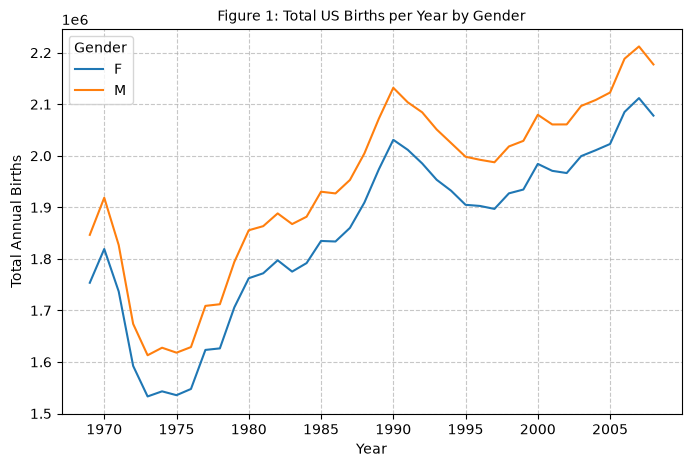

In [5]:
plt.figure(figsize=(8, 5))
births.pivot_table('births', index='year', columns='gender', aggfunc='sum').plot(ax=plt.gca())
plt.title('Figure 1: Total US Births per Year by Gender', fontsize=10)
plt.xlabel('Year', fontsize=10)
plt.ylabel('Total Annual Births', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Gender')
plt.show()

In [6]:
quartiles = np.percentile(births['births'], [25, 50, 75])
mu = quartiles[1]
sig = 0.74 * (quartiles[2] - quartiles[0])

print(f"Robust Mean (mu): {mu}")
print(f"Robust Std Dev (sig): {sig:.2f}")

initial_rows = len(births)
births = births.query('(births > @mu - 5 * @sig) & (births < @mu + 5 * @sig)')
removed_rows = initial_rows - len(births)
print(f"Rows before cleaning: {initial_rows}")
print(f"Rows after cleaning: {len(births)}")
print(f"Total rows removed: {removed_rows}")

births['day'] = births['day'].astype(int)
print("New dtype of 'day' column:", births['day'].dtype)

Robust Mean (mu): 4814.0
Robust Std Dev (sig): 689.31
Rows before cleaning: 15547
Rows after cleaning: 14610
Total rows removed: 937
New dtype of 'day' column: int64


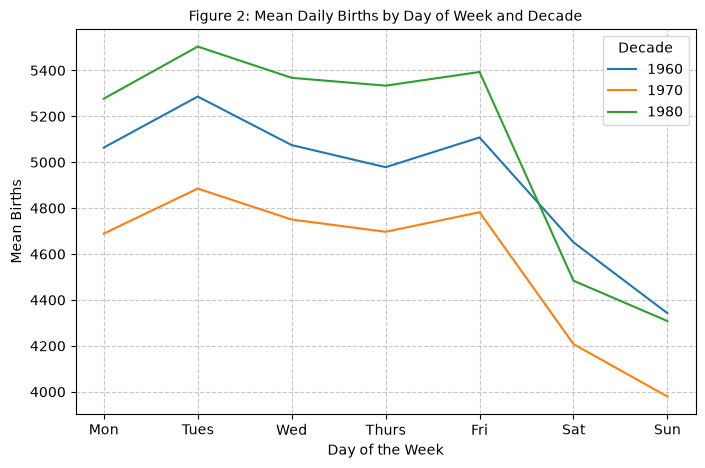

In [7]:
births.index = pd.to_datetime(10000 * births.year + 100 * births.month + births.day, format='%Y%m%d')
births['dayofweek'] = births.index.dayofweek

weekday_pivot = births.pivot_table('births', index='dayofweek', columns='decade', aggfunc='mean')

plt.figure(figsize=(8, 5))
weekday_pivot.plot(ax=plt.gca())
plt.gca().set_xticks(range(7))
plt.gca().set_xticklabels(['Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat', 'Sun'])
plt.title('Figure 2: Mean Daily Births by Day of Week and Decade', fontsize=10)
plt.xlabel('Day of the Week', fontsize=10)
plt.ylabel('Mean Births', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Decade')
plt.show()

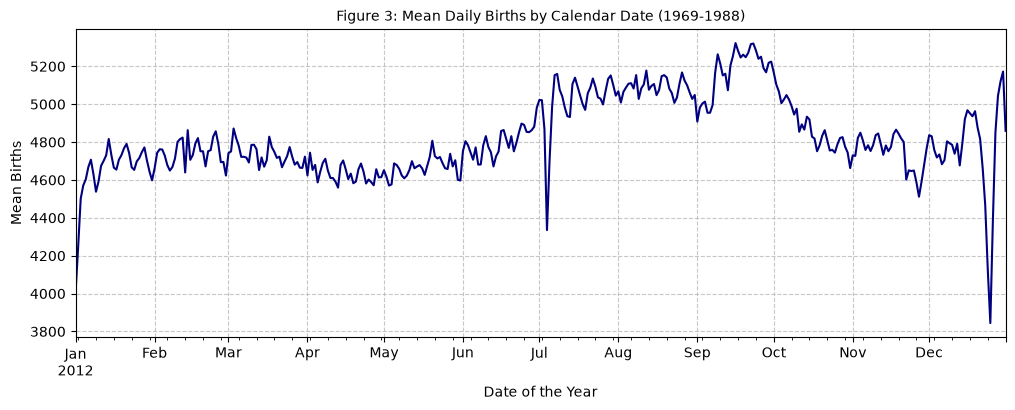

In [8]:
births_by_date = births.pivot_table('births', [births.index.month, births.index.day])

births_by_date.index = [pd.Timestamp(2012, month, day) for (month, day) in births_by_date.index]

fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, legend=False, color='navy')
plt.title('Figure 3: Mean Daily Births by Calendar Date (1969-1988)', fontsize=10)
plt.xlabel('Date of the Year', fontsize=10)
plt.ylabel('Mean Births', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [9]:
groupby_table = births.groupby(['decade', 'gender'])['births'].sum().unstack()
pivot_check = births.pivot_table('births', index='decade', columns='gender', aggfunc='sum')

print("Groupby + Unstack Result:\n", groupby_table)
print("\nDo both tables match exactly? ->", groupby_table.equals(pivot_check))

t_pivot = timeit.timeit(lambda: births.pivot_table('births', index='decade', columns='gender', aggfunc='sum'), number=1000) / 1000
t_group = timeit.timeit(lambda: births.groupby(['decade', 'gender'])['births'].sum().unstack(), number=1000) / 1000

print(f"\nAverage Pivot Table Time: {t_pivot:.6f} seconds")
print(f"Average GroupBy Time:     {t_group:.6f} seconds")

Groupby + Unstack Result:
 gender         F         M
decade                    
1960     1752836   1845742
1970    16260348  17118785
1980    16336507  17171290

Do both tables match exactly? -> True


KeyboardInterrupt: 

Five Calendar Dates with Lowest Mean Births:
December 25 : 3844.4 mean births
January 01 : 4009.2 mean births
December 24 : 4126.2 mean births
January 02 : 4247.4 mean births
July 04 : 4335.3 mean births


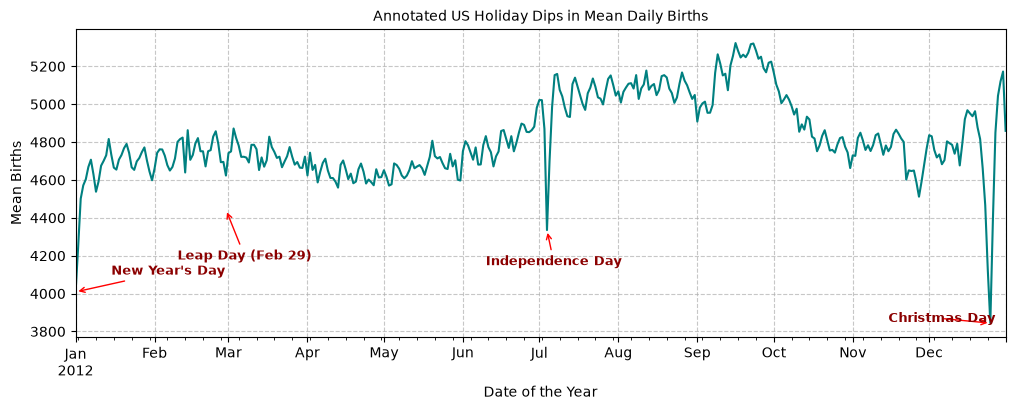

In [11]:
lowest_5 = births_by_date.sort_values(by='births').head(5)
print("Five Calendar Dates with Lowest Mean Births:")
for date, row in lowest_5.iterrows():
    print(f"{date.strftime('%B %d')} : {row['births']:.1f} mean births")

fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, legend=False, color='teal')

style = dict(size=9, color='darkred', weight='bold')

ax.annotate("New Year's Day", xy=('2012-1-1', 4009), xytext=('2012-1-15', 4100),
            arrowprops=dict(arrowstyle="->", color='red', lw=1), **style)
ax.annotate("Independence Day", xy=('2012-7-4', 4335), xytext=('2012-6-10', 4150),
            arrowprops=dict(arrowstyle="->", color='red', lw=1), **style)
ax.annotate("Christmas Day", xy=('2012-12-25', 3844), xytext=('2012-11-15', 3850),
            arrowprops=dict(arrowstyle="->", color='red', lw=1), **style)
ax.annotate("Leap Day (Feb 29)", xy=('2012-2-29', 4443), xytext=('2012-2-10', 4180),
            arrowprops=dict(arrowstyle="->", color='red', lw=1), **style)

plt.title('Annotated US Holiday Dips in Mean Daily Births', fontsize=10)
plt.xlabel('Date of the Year', fontsize=10)
plt.ylabel('Mean Births', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()